<a href="https://colab.research.google.com/github/gitmystuff/INFO5810/blob/main/Module_10-Anomalies/Module10_Anomaly_Mining_and_Distribution_Shift.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 10 — Anomaly Mining & Distribution Shift

## Getting Started

* Colab - get notebook from gitmystuff INFO5810 repository
* Save a Copy in Drive
* Remove Copy of
* Edit your name in the cell above and the filename
* Clean up Colab Notebooks folder
* Submit shared link


**Objective:** Learn practical ways to automatically flag
weird data points and detect when a dataset changes over time.

**Where this fits**

Module 9 built a Bayesian network for a single question: *given these clues,
how risky is this one claim?* Everything in that notebook quietly assumed one
thing it never said out loud -- that the network's CPTs are **correct and
stay correct over time**. That a claim with a 98% fraud-risk score genuinely is
high-risk depends entirely on the probabilities baked into the model still
describing the world.

This module is what happens the moment you stop trusting that assumption.
Two separate questions, both new:

1. **Within a single snapshot of data**, is this *one* data point weird
   compared to everything else? (Anomaly detection.)
2. **Comparing two snapshots over time**, has the *whole dataset* started
   looking different than it used to? (Distribution shift.)

Module 9 gave us a network built around **one claim, examined once.** You'd trace through it by hand: here are the causes, here are the clues, do they agree? For a single claim, sitting in front of you, that works fine.

This module addresses a couple of problems with this:

**Problem one: nobody actually reads every claim.** A real insurance company doesn't get one claim a week — they get thousands. The by-hand comparison from Module 9 only catches a contradiction if a person sits down, reads that specific claim, and notices the causes say one thing while the clues say another. At real volume, that doesn't happen. Most claims never get that kind of careful look. So in this module we will take that exact same comparison — do the causes and the clues agree — and turn it into a number a computer can compute for every claim automatically. Nothing new is being checked. It's the same question from Module 9, just asked of every row in a giant table instead of the one row we happened to be looking at in the last module.

**Problem two: the network's numbers don't stay true forever.** When we built the network in Module 9, we gave it specific numbers — something like "only 3% of claims with no history and ordinary timing turn out to be high risk."

That 3% is one specific cell in `FraudRisk`'s CPT from module 9. In the CPT, it's the row where `PriorClaims = No` and `SuspiciousTiming = No`:

| PriorClaims | SuspiciousTiming | FraudRisk=High | FraudRisk=Low |
|---|---|---|---|
| No | No | **0.03** | 0.97 |

That `0.03` is literally a number typed into the CPT when the network was built, same as every other cell in that table. Last time we just described one specific cell of it in plain words instead of calling it out as `P(FraudRisk=High | PriorClaims=No, SuspiciousTiming=No)`.

This is why we also do a drift check in this module: since that `0.03` is a specific, nameable cell in a specific table, "has it drifted" becomes a concrete, answerable question — re-measure that same cell from fresh claims and compare the new number to `0.03`, rather than something vague like "has fraud changed."

These numbers came from somewhere — some batch of real data, at some point in time. But the real world keeps moving. If a new kind of fraud shows up next year that doesn't trip the old causes, the true percentage might now be 22%, not 3% — and the network has no way of knowing that on its own. It just keeps using the old number forever, confidently, unless someone actively checks it. That's why in this module we re-measures those numbers against fresh data and compare them to what the network originally assumed, to catch the moment they've drifted.



## Part 0 — Setup

Everything here ships with Colab already -- no risky installs this week.
We'll use:

- `pgmpy` -- to rebuild the Module 9 fraud-risk network and sample a
  synthetic population of claims from it
- `scikit-learn` -- `IsolationForest` and `LocalOutlierFactor`, two
  general-purpose outlier detectors
- `scipy.stats` -- the Kolmogorov-Smirnov test, a standard statistical test
  for "do these two samples come from the same distribution?"


In [ ]:
%pip install -q pgmpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 6.9 MB/s eta 0:00:00


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.sampling import BayesianModelSampling
from pgmpy.estimators import MaximumLikelihoodEstimator
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

pd.set_option("display.width", 120)
plt.rcParams["figure.facecolor"] = "white"

print("Libraries loaded.")


/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


Libraries loaded.



### Rebuilding the Module 9 network

Same five nodes, same CPTs, same claim-risk story: `PriorClaims` and
`SuspiciousTiming` feed a hidden `FraudRisk`, which in turn produces two
observable clues, `MismatchedReceipts` and `WitnessInconsistency`.


In [ ]:

edges = [
    ("PriorClaims", "FraudRisk"),
    ("SuspiciousTiming", "FraudRisk"),
    ("FraudRisk", "MismatchedReceipts"),
    ("FraudRisk", "WitnessInconsistency"),
]

def build_fraud_model(fraud_cpt_values):
    cpd_prior = TabularCPD("PriorClaims", 2, [[0.15], [0.85]],
                            state_names={"PriorClaims": ["Yes", "No"]})
    cpd_timing = TabularCPD("SuspiciousTiming", 2, [[0.10], [0.90]],
                             state_names={"SuspiciousTiming": ["Yes", "No"]})
    cpd_fraud = TabularCPD(
        "FraudRisk", 2, fraud_cpt_values,
        evidence=["PriorClaims", "SuspiciousTiming"], evidence_card=[2, 2],
        state_names={"FraudRisk": ["High", "Low"], "PriorClaims": ["Yes", "No"],
                     "SuspiciousTiming": ["Yes", "No"]},
    )
    cpd_receipts = TabularCPD(
        "MismatchedReceipts", 2, [[0.75, 0.05], [0.25, 0.95]],
        evidence=["FraudRisk"], evidence_card=[2],
        state_names={"MismatchedReceipts": ["Yes", "No"], "FraudRisk": ["High", "Low"]},
    )
    cpd_witness = TabularCPD(
        "WitnessInconsistency", 2, [[0.65, 0.04], [0.35, 0.96]],
        evidence=["FraudRisk"], evidence_card=[2],
        state_names={"WitnessInconsistency": ["Yes", "No"], "FraudRisk": ["High", "Low"]},
    )
    m = DiscreteBayesianNetwork(edges)
    m.add_cpds(cpd_prior, cpd_timing, cpd_fraud, cpd_receipts, cpd_witness)
    assert m.check_model(), "model failed validation"
    return m

# the same CPT values from Module 9
FRAUD_CPT = [[0.90, 0.55, 0.50, 0.03],
             [0.10, 0.45, 0.50, 0.97]]

model = build_fraud_model(FRAUD_CPT)
cpds = {c.variable: c for c in model.get_cpds()}
print("Network rebuilt and validated.")

import itertools

def cpd_to_dataframe(cpd):
    # Same helper from Module 9 -- reads cpd.variables and cpd.values directly,
    # NOT cpd.get_evidence() (which returns evidence in reversed order and
    # would silently mislabel this table).
    var = cpd.variable
    var_states = cpd.state_names[var]
    evidence_vars = cpd.variables[1:]
    evidence_states = [cpd.state_names[e] for e in evidence_vars]
    rows = []
    for idx in itertools.product(*[range(len(s)) for s in evidence_states]):
        row = {ev: states[i] for ev, states, i in zip(evidence_vars, evidence_states, idx)}
        for vi, vs in enumerate(var_states):
            row[f"{var}={vs}"] = cpd.values[(vi,) + idx]
        rows.append(row)
    return pd.DataFrame(rows)


Network rebuilt and validated.



## Part 1 — What does "anomaly" mean?

Before building any detector, it's worth answering this directly: what makes
one data point anomalous and another one normal?

Here's the Bayesian-network answer, and it costs nothing extra -- the
machinery is already sitting in Module 9's factorization formula:

$$P(X_1, \dots, X_n) = \prod_{i=1}^{n} P(X_i \mid \text{parents}(X_i))$$

Plug in one *specific* claim -- an actual combination of all five variables --
and that product collapses to a single number: **how likely is this exact
combination, under everything the network believes about how these variables
relate to each other?** A combination the network considers implausible gets
a tiny number. This number is our anomaly score.

In our network, $X_1, \dots, X_n$ are just the five columns: `PriorClaims`, `SuspiciousTiming`, `FraudRisk`, `MismatchedReceipts`, `WitnessInconsistency`. The formula says: **the probability of one full, specific claim — a particular value for every single column at once — is just all five of that claim’s individual CPT numbers multiplied together, where each number is looked up conditioned on that variable’s own parents (or, for the two variables with no parents, just its plain prior).**

"Parents" refer to the causes feeding directly into that variable:

- `PriorClaims` and `SuspiciousTiming` have no parents (nothing points into them), so their "number" is just their plain prior — how common that value is in general.
- `FraudRisk`'s parents are `PriorClaims` and `SuspiciousTiming` — its number comes from the CPT row matching whatever those two came out as.
- `MismatchedReceipts` and `WitnessInconsistency` each have one parent, `FraudRisk` — their numbers come from the CPT row matching whatever `FraudRisk` came out as.

So for one specific claim, the formula is just: take that claim's value for each of the five columns, look up the matching CPT number for each one, multiply all five together.

Here's the actual contradiction example from earlier, with real numbers — no claim history, ordinary timing, but both clues showed up anyway:

$$P = \underbrace{0.85}_{P(\text{PriorClaims=No})} \times \underbrace{0.90}_{P(\text{SuspiciousTiming=No})} \times \underbrace{0.97}_{P(\text{FraudRisk=Low}\mid\text{No, No})} \times \underbrace{0.05}_{P(\text{Receipts=Yes}\mid\text{Low})} \times \underbrace{0.04}_{P(\text{Witness=Yes}\mid\text{Low})} = 0.001484$$

That tiny result — about 0.15% — is small specifically because the last two factors are small: given low risk, the CPT says receipts mismatching only happens 5% of the time, and witnesses disagreeing only happens 4% of the time. Multiplying those two small numbers is what makes our product even smaller and makes this claim's combination look implausible — which is exactly the point of using this formula as an anomaly score.


In [ ]:
def joint_prob_row(row, model=model, cpds=cpds):
    p = 1.0
    for node in model.nodes():
        cpd = cpds[node]
        kwargs = {node: row[node]}
        for parent in cpd.variables[1:]:
            kwargs[parent] = row[parent]
        p *= cpd.get_value(**kwargs)
    return p

# three hand-picked claims to build intuition before scoring a whole population
examples = {
    "all clean, low risk (the common case)":
        {"PriorClaims": "No", "SuspiciousTiming": "No", "FraudRisk": "Low",
         "MismatchedReceipts": "No", "WitnessInconsistency": "No"},
    "typical high-risk (rare causes, but consistent with them)":
        {"PriorClaims": "Yes", "SuspiciousTiming": "Yes", "FraudRisk": "High",
         "MismatchedReceipts": "Yes", "WitnessInconsistency": "Yes"},
    "both causes present, but risk comes out low anyway, and both clues show up anyway":
        {"PriorClaims": "Yes", "SuspiciousTiming": "Yes", "FraudRisk": "Low",
         "MismatchedReceipts": "Yes", "WitnessInconsistency": "Yes"},
}

for label, row in examples.items():
    print(f"{label:70s} P = {joint_prob_row(row):.6f}")

all clean, low risk (the common case)                                  P = 0.676750
typical high-risk (rare causes, but consistent with them)              P = 0.006581
both causes present, but risk comes out low anyway, and both clues show up anyway P = 0.000003


Here are what the two claims might look like with joint probabilities:

| PriorClaims | SuspiciousTiming | FraudRisk | MismatchedReceipts | WitnessInconsistency | joint probability | flagged? |
|---|---|---|---|---|---|---|
| No | No | Low | No | No | 0.676750 | No |
| Yes | Yes | **Low** | Yes | Yes | **0.000003** | **Yes** |

**Step 1 — what the formula actually computes, for the flagged row.** The joint probability formula says: look up one number for each of the five columns, multiply all five together. Each number comes from that variable's own CPT row, conditioned on its own parents:

| what's being looked up | CPT row used | number |
|---|---|---|
| P(PriorClaims=Yes) | root prior | 0.15 |
| P(SuspiciousTiming=Yes) | root prior | 0.10 |
| P(FraudRisk=Low \| Yes, Yes) | PriorClaims=Yes, SuspiciousTiming=Yes row | 0.10 |
| P(MismatchedReceipts=Yes \| Low) | FraudRisk=Low row | 0.05 |
| P(WitnessInconsistency=Yes \| Low) | FraudRisk=Low row | 0.04 |

Multiply them: $0.15 \times 0.10 \times 0.10 \times 0.05 \times 0.04 = 0.000003$ — the number that results in this row being flagged.

**Step 2 — why that number is so small.** Every factor in that chain works against this claim. Having a claims history and suspicious timing is uncommon on its own (0.15 and 0.10). Given those two red flags, the CPT says 90% of such claims turn out high-risk — this one didn't; it landed in the 10% minority. And despite being low-risk, both clues showed up anyway, which only happens 5% and 4% of the time respectively. None of these five things is impossible alone. What drives the score down is that **all five landed on the unlikely side, together, on this one claim.**

**Step 3 — why this is what "anomaly" means here, and why the first row isn't one.** A CPT row never shows an anomaly — it's just a rule describing the population (10% of such claims turn out low-risk; that's unremarkable on its own). The first row above — no history, ordinary timing, low risk, nothing unusual observed — is the common case, every factor landing where most claims land, which is exactly why its score is high (0.68). The second row is an anomaly specifically because it's one actual case that landed on the unlikely branch at every decision point, not just one. The gap between 0.68 and 0.000003 — roughly 200,000-fold — is the anomaly signal itself.

**Step 4 — how this connects to the tools in this module.** Spotting the second row by reading it carefully is something a person could do by hand: notice both causes are red flags, notice the outcome doesn't match them, notice the clues don't match the outcome either. The techniques in this module, takes that exact reasoning and turns it into the "joint probability" column above, computed automatically for every claim in a batch of thousands. Sort by that column, and rows like the second one surface at the bottom without anyone having had to read them individually — the human reasoning doesn't change, it just gets applied at a scale no person could manage alone.

In [ ]:

sampler = BayesianModelSampling(model)
normal_claims = sampler.forward_sample(size=3000, seed=0, show_progress=False)
normal_claims["is_injected"] = False

# 15 deliberately contradictory claims: Low risk, but both clues fire anyway --
# exactly the pattern the network itself considers implausible
rng = np.random.default_rng(1)
n_inject = 15
injected_claims = pd.DataFrame({
    "PriorClaims": rng.choice(["Yes", "No"], n_inject, p=[0.15, 0.85]),
    "SuspiciousTiming": rng.choice(["Yes", "No"], n_inject, p=[0.10, 0.90]),
    "FraudRisk": ["Low"] * n_inject,
    "MismatchedReceipts": ["Yes"] * n_inject,
    "WitnessInconsistency": ["Yes"] * n_inject,
    "is_injected": [True] * n_inject,
})

claims = pd.concat([normal_claims, injected_claims], ignore_index=True)
claims["joint_prob"] = claims.apply(joint_prob_row, axis=1)

threshold = claims["joint_prob"].quantile(0.01)
claims["flagged_by_bn"] = claims["joint_prob"] <= threshold

caught = claims.loc[claims["is_injected"], "flagged_by_bn"].sum()
print(f"Bottom-1% joint-probability threshold: {threshold:.6f}")
print(f"Total claims flagged: {claims['flagged_by_bn'].sum()} out of {len(claims)}")
print(f"Injected contradictory claims caught: {caught} out of {n_inject}")


Bottom-1% joint-probability threshold: 0.001615
Total claims flagged: 35 out of 3015
Injected contradictory claims caught: 15 out of 15


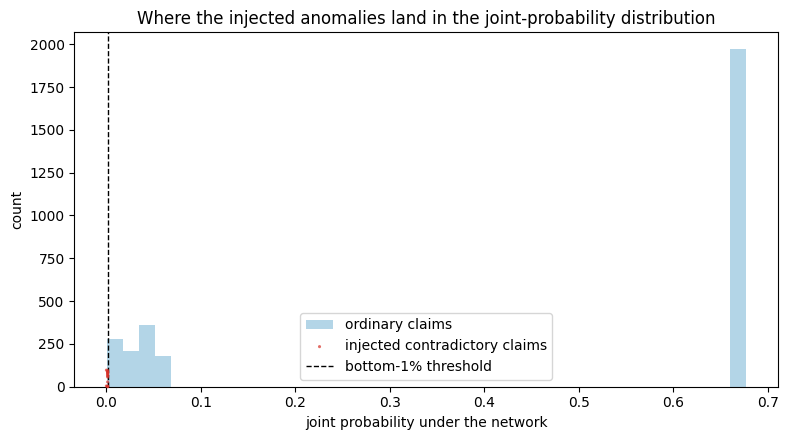

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(claims.loc[~claims["is_injected"], "joint_prob"], bins=40, color="#a6cee3",
        label="ordinary claims", alpha=0.85)

# several injected claims land on the exact same score (same PriorClaims/
# SuspiciousTiming combination by chance), so plain markers would stack
# invisibly on top of each other -- a little jitter in both directions
# turns that hidden stack into a visible cloud of points
top = ax.get_ylim()[1]
rng_display = np.random.default_rng(0)
injected_scores = claims.loc[claims["is_injected"], "joint_prob"].values
jitter_y = rng_display.uniform(0, top * 0.05, len(injected_scores))
jitter_x = rng_display.normal(0, injected_scores.std() * 0.1 + 1e-6, len(injected_scores))

ax.scatter(injected_scores + jitter_x, jitter_y, color="#d73027", s=5, zorder=5,
           label="injected contradictory claims", marker="o", alpha=0.7,
           edgecolors="none", clip_on=False)
ax.set_ylim(0, top)

ax.axvline(threshold, color="black", linestyle="--", linewidth=1,
           label="bottom-1% threshold")
ax.set_xlabel("joint probability under the network")
ax.set_ylabel("count")
ax.set_title("Where the injected anomalies land in the joint-probability distribution")
ax.legend()
plt.tight_layout()
plt.show()

**1 — build the claims and check which ones stand out**

First, the computer makes 3,000 ordinary claims. For each one, it picks every value — causes and clues — using the real percentages from the CPTs, the same way it would happen naturally.

Then it makes 15 claims by hand instead. These are built to be the kind we talked about: no claim history, ordinary timing, low risk — but both clues show up anyway. We mark these 15 so we can check later whether they get caught.

Next, all 3,015 claims get combined into one table. Every single row gets a joint probability score — the same multiplication from before, done once per claim.

Then we pick a cutoff: whatever score only the lowest 1% of all claims fall under. Any claim at or below that score gets marked as flagged.

Last, we check: of the 15 claims we built by hand, how many actually got flagged?

**2 — draw the picture**

Most of the chart is a bar graph showing where the 3,000 ordinary claims' scores land. Then a red X gets placed for each of the 15 hand-built claims, at its actual score. Last, a dashed line marks the cutoff. If the red Xs are to the left of the dashed line, they got flagged — which is what the chart lets you see at a glance.



## Part 2 — A geometric answer to the same question

The joint-probability approach needs a Bayesian network, which means it
needs someone to have already worked out the causal structure and the CPTs.
Most of the time, you won't have that. What you'll have instead is a table
of numbers and a question: which rows look weird?

`scikit-learn` gives us two standard, general-purpose answers that need no
causal model at all -- just a notion of "distance" or "density" in feature
space:

- **`IsolationForest`**: repeatedly splits the data at random; points that
  get isolated into their own tiny region after very few splits are
  flagged as outliers. Outliers are, almost by definition, easy to separate
  from everything else.
- **`LocalOutlierFactor`**: compares each point's local density (how packed
  together its nearest neighbors are) to its neighbors' own local density.
  A point sitting in a much sparser neighborhood than its surroundings is
  flagged.

We'll switch to two continuous features for this -- claim amount in dollars,
and how many days after the claim was filed relative to when it happened.


In [ ]:

rng = np.random.default_rng(42)
n_normal = 500

# ordinary claims: filing takes a little while, and bigger claims tend to
# take slightly longer to put together
days_to_file = rng.gamma(shape=4, scale=5, size=n_normal)       # mean ~20 days
claim_amount = 300 + days_to_file * 40 + rng.normal(0, 400, n_normal)
claim_amount = np.clip(claim_amount, 100, None)

normal_df = pd.DataFrame({
    "days_to_file": days_to_file,
    "claim_amount": claim_amount,
    "is_injected": False,
})

# genuine outliers: filed almost instantly, for an enormous amount --
# isolated in feature space, not just "a bit unusual"
n_outliers = 12
outlier_days = rng.uniform(0, 1, n_outliers)
outlier_amount = rng.uniform(15000, 25000, n_outliers)
outlier_df = pd.DataFrame({
    "days_to_file": outlier_days,
    "claim_amount": outlier_amount,
    "is_injected": True,
})

geo_claims = pd.concat([normal_df, outlier_df], ignore_index=True)
X = geo_claims[["days_to_file", "claim_amount"]].values

iso = IsolationForest(contamination=0.02, random_state=0)
geo_claims["flagged_iso"] = iso.fit_predict(X) == -1

lof = LocalOutlierFactor(n_neighbors=20, contamination=0.02)
geo_claims["flagged_lof"] = lof.fit_predict(X) == -1

caught_iso = geo_claims.loc[geo_claims["is_injected"], "flagged_iso"].sum()
caught_lof = geo_claims.loc[geo_claims["is_injected"], "flagged_lof"].sum()
print(f"IsolationForest caught {caught_iso} of {n_outliers} injected outliers")
print(f"LocalOutlierFactor caught {caught_lof} of {n_outliers} injected outliers")


IsolationForest caught 9 of 12 injected outliers
LocalOutlierFactor caught 11 of 12 injected outliers


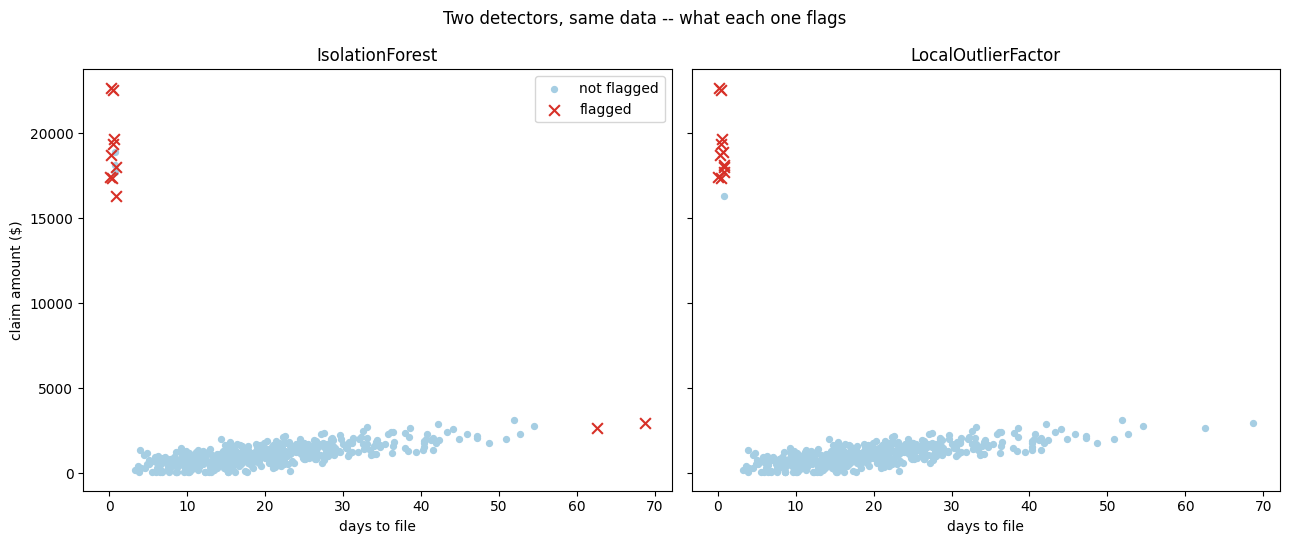

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)

for ax, flag_col, name in zip(axes, ["flagged_iso", "flagged_lof"],
                                ["IsolationForest", "LocalOutlierFactor"]):
    normal_pts = geo_claims[~geo_claims[flag_col]]
    flagged_pts = geo_claims[geo_claims[flag_col]]
    ax.scatter(normal_pts["days_to_file"], normal_pts["claim_amount"],
               s=18, color="#a6cee3", label="not flagged")
    ax.scatter(flagged_pts["days_to_file"], flagged_pts["claim_amount"],
               s=60, color="#d73027", marker="x", label="flagged")
    ax.set_xlabel("days to file")
    ax.set_title(name)

axes[0].set_ylabel("claim amount ($)")
axes[0].legend()
plt.suptitle("Two detectors, same data -- what each one flags")
plt.tight_layout()
plt.show()



Neither detector caught every single injected outlier, and that's worth
noticing rather than glossing over -- real outlier detection is probabilistic,
not perfect, and the two methods don't always agree on the edge cases. That's
a genuine, honest property of these tools, not a bug in this demo.


**Where the two panels disagree:**
- In the **IsolationForest** panel (left), two extra claims get flagged way out on the right — filed 60-70 days later, for an ordinary amount around $2,700-3,000. Nothing about those two was planted as an outlier; `IsolationForest` just happened to consider them unusual enough (sitting a bit apart from the main crowd of dots) to flag anyway. That's a false positive.
- In the **LocalOutlierFactor** panel (right), those two far-right claims are left blue — not flagged — and LOF catches one more point in the top-left cluster that IsolationForest missed (visible as one extra red X up there, one fewer blue dot).

These two general-purpose tools, run on the exact same data, but don't produce identical answers. One over-flags in a spot the other doesn't; the other catches one real case the first one misses. Neither is wrong, exactly — they're just built on different ideas (isolating points with random splits vs. comparing local density to neighbors), and real outlier detection means living with that kind of disagreement rather than expecting one tool to be definitively correct.


## Part 3 — Has the world changed? Catching drift with the network itself

Part 1 asked "is this one claim currently an anomaly, right now?" This part asks something different: **has the underlying pattern of fraud itself changed since the network's CPTs were set?**

Here's the direct, Module-9-native way to check: take a fresh batch of
claims from a new time period, and re-estimate the CPTs from scratch using
only that new data -- `MaximumLikelihoodEstimator` reads conditional
probabilities straight off frequency counts. If the re-estimated numbers
come back close to the original CPT, nothing's changed. If they come back
different, that's drift, measured in the same units the network already
speaks in.

We'll simulate a believable scenario: last month's claims came from the
original network. This month, a new scam technique emerged that doesn't
trip the old history/timing signals -- clean-looking claims (no prior
claims, normal timing) now carry much higher real risk than they used to.


In [ ]:

# last month: the original CPT from Module 9
model_last_month = build_fraud_model([[0.90, 0.55, 0.50, 0.03],
                                       [0.10, 0.45, 0.50, 0.97]])

# this month: P(FraudRisk=High | clean history, normal timing) jumped from
# 0.03 to 0.22 -- a new fraud pattern that doesn't trip the old signals
model_this_month = build_fraud_model([[0.90, 0.55, 0.50, 0.22],
                                       [0.10, 0.45, 0.50, 0.78]])

data_last_month = BayesianModelSampling(model_last_month).forward_sample(
    size=4000, seed=1, show_progress=False)
data_this_month = BayesianModelSampling(model_this_month).forward_sample(
    size=4000, seed=2, show_progress=False)

print("4000 simulated claims sampled for each time window.")


4000 simulated claims sampled for each time window.


In [ ]:

# re-estimate FraudRisk's CPT separately from each window's data, assuming
# NOTHING about what the true CPT is -- just reading it off the data
cpd_reestimated_last = MaximumLikelihoodEstimator(
    model_last_month, data_last_month).estimate_cpd("FraudRisk")
cpd_reestimated_this = MaximumLikelihoodEstimator(
    model_this_month, data_this_month).estimate_cpd("FraudRisk")

print("Re-estimated from last month's data:")
display(cpd_to_dataframe(cpd_reestimated_last))
print()
print("Re-estimated from this month's data:")
display(cpd_to_dataframe(cpd_reestimated_this))


Re-estimated from last month's data:


/tmp/ipykernel_726/2562441533.py:3: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  cpd_reestimated_last = MaximumLikelihoodEstimator(
/tmp/ipykernel_726/2562441533.py:5: FutureWarning: `pgmpy.estimators.MaximumLikelihoodEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteMLE` instead.
  cpd_reestimated_this = MaximumLikelihoodEstimator(


,PriorClaims,SuspiciousTiming,FraudRisk=High,FraudRisk=Low
0,No,No,0.030392,0.969608
1,No,Yes,0.509804,0.490196
2,Yes,No,0.525520,0.474480
3,Yes,Yes,0.907407,0.092593



Re-estimated from this month's data:


,PriorClaims,SuspiciousTiming,FraudRisk=High,FraudRisk=Low
0,No,No,0.223143,0.776857
1,No,Yes,0.488064,0.511936
2,Yes,No,0.561468,0.438532
3,Yes,Yes,0.870968,0.129032


In [ ]:

p_last = cpd_reestimated_last.get_value(FraudRisk="High", PriorClaims="No", SuspiciousTiming="No")
p_this = cpd_reestimated_this.get_value(FraudRisk="High", PriorClaims="No", SuspiciousTiming="No")

print("P(FraudRisk = High | PriorClaims = No, SuspiciousTiming = No)")
print(f"  re-estimated from last month's data: {p_last:.4f}   (true value baked in: 0.03)")
print(f"  re-estimated from this month's data: {p_this:.4f}   (true value baked in: 0.22)")
print()
print(f"Shift detected: {p_this - p_last:+.4f}")


P(FraudRisk = High | PriorClaims = No, SuspiciousTiming = No)
  re-estimated from last month's data: 0.0304   (true value baked in: 0.03)
  re-estimated from this month's data: 0.2231   (true value baked in: 0.22)

Shift detected: +0.1928


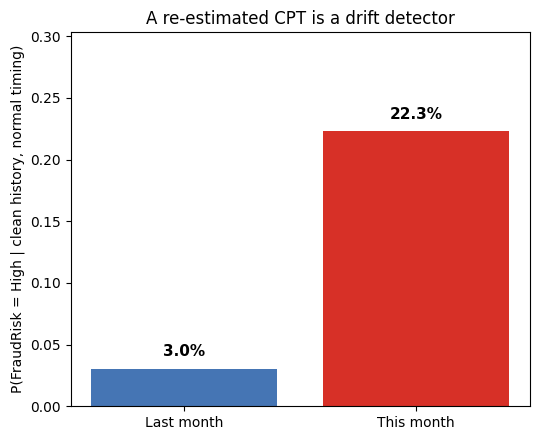

In [ ]:

fig, ax = plt.subplots(figsize=(5.5, 4.5))
bars = ax.bar(["Last month", "This month"], [p_last, p_this],
              color=["#4575b4", "#d73027"])
for bar, v in zip(bars, [p_last, p_this]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.1%}",
            ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, max(p_last, p_this) + 0.08)
ax.set_ylabel("P(FraudRisk = High | clean history, normal timing)")
ax.set_title("A re-estimated CPT is a drift detector")
plt.tight_layout()
plt.show()



This is exactly the kind of thing a fraud team would actually want flagged:
a whole category of claims that used to be safely ignorable is, as of this
month, meaningfully riskier -- and nothing about the *old* detection signals
(prior claims, suspicious timing) would ever catch it, because the shift is
happening precisely in the claims that look clean on those signals. Only
re-checking the model's own numbers against fresh data surfaces it.



## Part 4 — General-purpose drift detection: when you don't have a CPT to re-check

Re-estimating a CPT only works when you have a Bayesian network in the first
place. Most of the time, what you actually have is a column of numbers --
say, claim amounts -- and the same underlying question: does this month's
column look like last month's column?

Two standard, model-free tools answer exactly that:

- **The Kolmogorov-Smirnov (KS) test** -- a formal statistical test for
  "did these two samples come from the same distribution?" It returns a
  p-value; a very small p-value means the difference is unlikely to be due
  to random sampling alone.
- **Population Stability Index (PSI)** -- an industry-standard practical
  metric (common in credit risk and fraud teams) that buckets both samples
  into bins and measures how much probability mass moved between bins.
  Conventional thresholds: **PSI < 0.1** is considered no meaningful
  change, **0.1-0.25** is a moderate shift worth watching, and **PSI > 0.25**
  is a major shift.

We'll test both on claim amounts, once where nothing actually changed
(just a fresh random sample from the same distribution) and once where
amounts genuinely rose 35% -- simulating something like inflation or a new
higher-value fraud pattern.


In [ ]:

rng = np.random.default_rng(7)

def simulate_claim_amounts(n, multiplier=1.0, seed=None):
    r = np.random.default_rng(seed)
    amounts = 300 + r.gamma(shape=4, scale=5, size=n) * 40 + r.normal(0, 400, n)
    return np.clip(amounts, 100, None) * multiplier

last_month_amounts = simulate_claim_amounts(2000, seed=10)
this_month_no_shift = simulate_claim_amounts(2000, seed=11)         # same distribution
this_month_shifted = simulate_claim_amounts(2000, multiplier=1.35, seed=12)  # +35%

stat_no_shift, p_no_shift = ks_2samp(last_month_amounts, this_month_no_shift)
stat_shift, p_shift = ks_2samp(last_month_amounts, this_month_shifted)

print("KS test -- last month vs. this month, NO real shift:")
print(f"  statistic = {stat_no_shift:.4f}   p-value = {p_no_shift:.4f}")
print()
print("KS test -- last month vs. this month, 35% amount increase:")
print(f"  statistic = {stat_shift:.4f}   p-value = {p_shift:.2e}")


KS test -- last month vs. this month, NO real shift:
  statistic = 0.0385   p-value = 0.1032

KS test -- last month vs. this month, 35% amount increase:
  statistic = 0.2625   p-value = 5.73e-61


In [ ]:

def psi(expected, actual, bins=10):
    # bin edges are derived from EXPECTED and then reused for BOTH samples --
    # this is the detail Part 5 breaks on purpose
    breakpoints = np.quantile(expected, np.linspace(0, 1, bins + 1))
    breakpoints[0], breakpoints[-1] = -np.inf, np.inf
    exp_counts, _ = np.histogram(expected, bins=breakpoints)
    act_counts, _ = np.histogram(actual, bins=breakpoints)
    exp_pct = np.clip(exp_counts / len(expected), 1e-6, None)
    act_pct = np.clip(act_counts / len(actual), 1e-6, None)
    return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct)))

psi_no_shift = psi(last_month_amounts, this_month_no_shift)
psi_shift = psi(last_month_amounts, this_month_shifted)

print(f"PSI -- no real shift:  {psi_no_shift:.4f}  (below 0.1 -> no meaningful change)")
print(f"PSI -- 35% shift:      {psi_shift:.4f}  (above 0.25 -> major shift)")


PSI -- no real shift:  0.0082  (below 0.1 -> no meaningful change)
PSI -- 35% shift:      0.3843  (above 0.25 -> major shift)


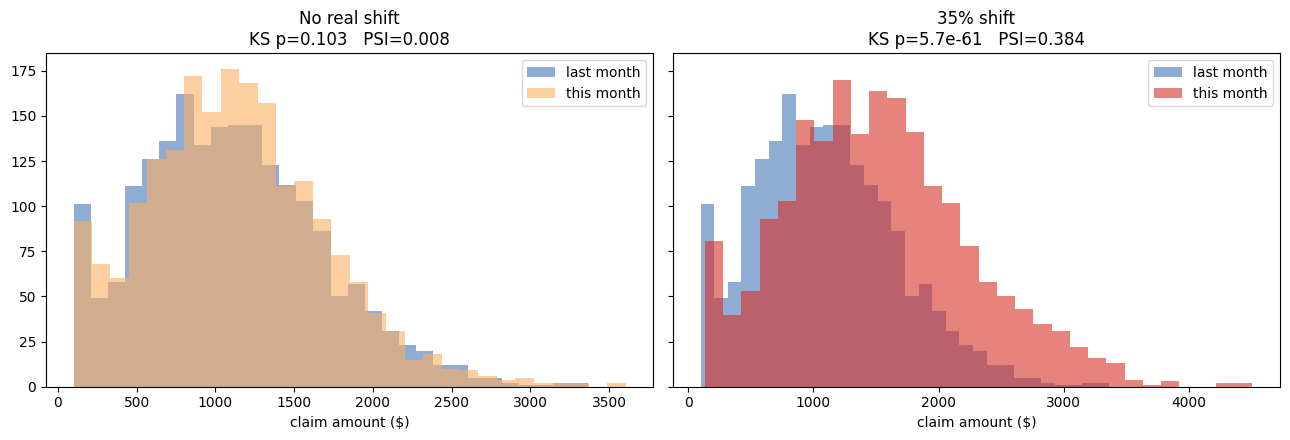

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)

axes[0].hist(last_month_amounts, bins=30, alpha=0.6, label="last month", color="#4575b4")
axes[0].hist(this_month_no_shift, bins=30, alpha=0.6, label="this month", color="#fdae61")
axes[0].set_title(f"No real shift\nKS p={p_no_shift:.3f}   PSI={psi_no_shift:.3f}")
axes[0].set_xlabel("claim amount ($)")
axes[0].legend()

axes[1].hist(last_month_amounts, bins=30, alpha=0.6, label="last month", color="#4575b4")
axes[1].hist(this_month_shifted, bins=30, alpha=0.6, label="this month", color="#d73027")
axes[1].set_title(f"35% shift\nKS p={p_shift:.1e}   PSI={psi_shift:.3f}")
axes[1].set_xlabel("claim amount ($)")
axes[1].legend()

plt.tight_layout()
plt.show()



Both tools agree cleanly here: nothing meaningful in the left panel, a loud
alarm in the right one. That agreement is exactly what you want from two
independently-built tools -- it's also exactly what the next section breaks.



## Part 5 — Quiet bug: PSI with mismatched bins

PSI's whole design depends on one detail that's easy to get wrong: both
samples need to be sorted into **the exact same bins**. The function above
computes bin edges once, from `expected`, and reuses those same edges for
`actual`. Here's the realistic mistake: computing bin edges **separately**
for each sample instead -- which looks almost identical in code, runs
without any error, and produces a plausible-looking float.


In [ ]:

def psi_buggy(expected, actual, bins=10):
    # BUG: bin edges computed independently for each sample, instead of
    # reusing expected's edges for both
    exp_breaks = np.quantile(expected, np.linspace(0, 1, bins + 1))
    act_breaks = np.quantile(actual, np.linspace(0, 1, bins + 1))      # <-- the mistake
    exp_breaks[0], exp_breaks[-1] = -np.inf, np.inf
    act_breaks[0], act_breaks[-1] = -np.inf, np.inf
    exp_counts, _ = np.histogram(expected, bins=exp_breaks)
    act_counts, _ = np.histogram(actual, bins=act_breaks)
    exp_pct = np.clip(exp_counts / len(expected), 1e-6, None)
    act_pct = np.clip(act_counts / len(actual), 1e-6, None)
    return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct)))

psi_correct_result = psi(last_month_amounts, this_month_shifted)
psi_buggy_result = psi_buggy(last_month_amounts, this_month_shifted)

print("Same two samples. Same real 35% shift. Two different PSI implementations:")
print(f"  correct PSI (shared bin edges):      {psi_correct_result:.4f}  -> flags a major shift")
print(f"  buggy PSI (independent bin edges):   {psi_buggy_result:.4f}  -> looks like nothing happened")


Same two samples. Same real 35% shift. Two different PSI implementations:
  correct PSI (shared bin edges):      0.3843  -> flags a major shift
  buggy PSI (independent bin edges):   0.0000  -> looks like nothing happened



No error, no warning, a clean-looking number -- and it's reporting that a
genuine, 35%-across-the-board shift in claim amounts is completely
unremarkable. The bug is structural, not numerical: when each sample gets
its own independently-computed equal-frequency bins, **every bin always
contains close to the same fraction of its own sample, by construction** --
10% in each of 10 bins, always, no matter how far the two distributions have
actually drifted apart. The bins silently "follow" the data instead of
holding still as a fixed yardstick, so PSI's whole measurement -- "how much
probability mass moved between fixed buckets" -- never gets a chance to
register anything.

**Working rule:** any metric that compares two samples through a shared
scaffolding -- bins, a fitted threshold, a trained reference model -- is
only valid if that scaffolding was built **once**, from a trusted reference,
and then held fixed. The moment each side quietly gets to redefine its own
scaffolding, the comparison stops measuring the thing you think it's
measuring, and it will not tell you so.



## Part 6 — Wrap-up

What this module adds to Module 9, in one sentence: Module 9 trusted the
model; Module 10 is the discipline of checking whether that trust is still
earned.

Quick recap:

1. **Joint probability as an anomaly score** -- the same factorization
   formula that powers inference also scores how plausible a specific
   combination of values is, with zero new modeling effort.
   Yes — exactly that, with one small precision worth nailing down.

 > Bayes' theorem is usually written:

  $$P(A \mid B) = \frac{P(B \mid A)\,P(A)}{P(B)}$$

 > But $P(B\mid A)\,P(A)$ is just another way of writing the joint probability $P(A,B)$ — that's literally the definition of a joint probability (chain rule with two variables). So you can just as correctly write Bayes' theorem as:

  $$P(A \mid B) = \frac{P(A,B)}{P(B)}$$

 > The numerator is "how often A and B happen together," and the denominator is "how often B happens at all" — dividing one by the other restricts your attention to just the B-world and asks what fraction of it is also A.

 > One thing to be careful about, our `joint_prob_row`computes the joint probability over **all five** variables at once, for one specific claim. The joint probability in Bayes' theorem's numerator is usually over just the two variables you're asking about (or however many are on each side).

2. **IsolationForest and LocalOutlierFactor** -- general-purpose, model-free
   outlier detectors that work from geometry (isolation, local density)
   instead of a causal structure, for the much more common case where you
   don't have a Bayesian network handy. Neither is perfect, and that's a
   real property of outlier detection, not a flaw in this demo.
3. **Re-estimating a CPT on fresh data** -- the most direct way to catch
   drift when you do have a causal model: compare what the model *used to*
   believe against what the current data actually says.
4. **The KS-test and PSI** -- the general-purpose equivalents, for columns
   of numbers with no causal model behind them at all. PSI's conventional
   thresholds (0.1, 0.25) give a quick, standard read.
5. **Quiet bugs are still here** -- this time hiding in a comparison tool's
   own scaffolding silently shifting out from under it, rather than in a
   CPT's column order or an edge's distance convention.

**Where this goes next:** every technique in this module assumed you
already had *labeled structure* to compare against -- a trained network, a
reference time window, a known-good distribution. The deeper question
underneath all of it -- how do you even build that reference in the first
place, from raw data, with no one handing you the "correct" baseline -- is
exactly what unsupervised learning and clustering address, and it's a
natural place for this course to head next.
